# Task 1: Thesis Model Comparison and Reproducibility Audit
**By:** Margorie Fernanda Pérez Simba

## Objective

This notebook evaluates Random Forest as an initial candidate model for the predictive component of the doctoral research. Its performance is compared with Logistic Regression as a transparent baseline and a Dummy Classifier as the minimum reference. The notebook also demonstrates why reproducibility does not necessarily imply methodological validity.

## 1- Computational Environment and Dataset

In [ ]:
import platform, warnings, numpy as np, pandas as pd, sklearn
warnings.filterwarnings("ignore")
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier #New model
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__)
X, y = load_breast_cancer(return_X_y=True)
print("Patients / Pacientes:", X.shape[0], "| Features / Variables:", X.shape[1],
      "| Malignant / Malignos:", (y == 0).sum(), "| Benign / Benignos:", (y == 1).sum())

Python 3.13.16 | scikit-learn 1.6.1
Patients / Pacientes: 569 | Features / Variables: 30 | Malignant / Malignos: 212 | Benign / Benignos: 357


## 2- Reproduction of the Reference Claim

In [ ]:
def paper_pipeline(seed):
    rng = np.random.default_rng(seed)
    # 1) Copy minority patients to balance classes ... BEFORE splitting  (problem!)
    #    Copiar pacientes minoritarios ... ANTES de dividir               (¡problema!)
    minority = np.where(y == 0)[0]
    extra = rng.choice(minority, (y == 1).sum() - len(minority), replace=True)
    Xo, yo = np.vstack([X, X[extra]]), np.concatenate([y, y[extra]])
    # 2) Scale and select features using ALL rows ... BEFORE splitting  (problem!)
    #    Escalar y seleccionar con TODAS las filas ... ANTES de dividir (¡problema!)
    Xo = StandardScaler().fit_transform(Xo)
    Xo = SelectKBest(f_classif, k=10).fit_transform(Xo, yo)
    # 3) One 80/20 split with one seed / Una sola división 80/20 con una semilla
    Xtr, Xte, ytr, yte = train_test_split(Xo, yo, test_size=0.2, random_state=seed)
    m = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=seed).fit(Xtr, ytr)
    return accuracy_score(yte, m.predict(Xte))

print(f"Step 2 · Re-run with seed 12 / Re-ejecución con semilla 12: {paper_pipeline(12):.1%}")

Step 2 · Re-run with seed 12 / Re-ejecución con semilla 12: 100.0%


## 3- Methodological Audit of the Reference Workflow

### 3.1 Sensitivity to the Random Seed

In [ ]:
# (a) Try the paper's exact method with 20 seeds / Probar el método exacto con 20 semillas
res = pd.Series({s: paper_pipeline(s) for s in range(20)})
print(res.round(3).to_string())
print(f"\nIs seed 12 the best? / ¿La semilla 12 es la mejor?: {res.idxmax() == 12}")
print(f"Average / Promedio: {res.mean():.1%}   Worst / Peor: {res.min():.1%}")

0     0.972
1     0.965
2     0.951
3     0.972
4     0.979
5     0.972
6     0.979
7     0.979
8     0.958
9     0.979
10    0.979
11    0.965
12    1.000
13    0.951
14    0.944
15    0.937
16    0.979
17    0.965
18    0.972
19    0.972

Is seed 12 the best? / ¿La semilla 12 es la mejor?: True
Average / Promedio: 96.9%   Worst / Peor: 93.7%


### 3.2 Duplicate Observations Across Data Partitions

In [ ]:
# (b) Same patient in train AND test? / ¿Mismo paciente en entrenamiento Y prueba?
rng = np.random.default_rng(12)
minority = np.where(y == 0)[0]
extra = rng.choice(minority, (y == 1).sum() - len(minority), replace=True)
patient_id = np.concatenate([np.arange(len(y)), extra])     # real patient behind each row
tr_idx, te_idx = train_test_split(np.arange(len(patient_id)), test_size=0.2, random_state=12)
shared = set(patient_id[tr_idx]) & set(patient_id[te_idx])
dup = np.array([p in shared for p in patient_id[te_idx]])
print(f"Test rows / Filas de prueba: {len(te_idx)}")
print(f"Test rows whose patient is ALSO in training / Filas cuyo paciente TAMBIÉN está en entrenamiento: {dup.sum()} ({dup.mean():.0%})")

Test rows / Filas de prueba: 143
Test rows whose patient is ALSO in training / Filas cuyo paciente TAMBIÉN está en entrenamiento: 41 (29%)


### 3.3 Data Leakage Assessment

The audit identifies three main problems:

1. Dependence on a favorable random seed.
2. Duplicate patients in the training and test sets.
3. Data leakage during preprocessing and feature selection.

## 4- Corrected Model Comparison

In [ ]:
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=2026
)

models = {
    "Dumb model: always guess 'benign' / Modelo tonto":
        DummyClassifier(strategy="most_frequent"),

    "Baseline: logistic regression / Modelo base":
        make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=5000)
        ),

    "Candidate thesis model: Random Forest / Modelo candidato de tesis":
        RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=2026,
            n_jobs=-1
        ),
}

rows = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    rows.append({
        "Model / Modelo": name,
        "Mean / Media": scores.mean(),
        "SD / DE": scores.std(ddof=1),
        "Tests": len(scores)
    })

report = pd.DataFrame(rows).set_index("Model / Modelo")
print(report.round(3).to_string())

                                                                   Mean / Media  SD / DE  Tests
Model / Modelo                                                                                 
Dumb model: always guess 'benign' / Modelo tonto                          0.627    0.004     50
Baseline: logistic regression / Modelo base                               0.978    0.014     50
Candidate thesis model: Random Forest / Modelo candidato de tesis         0.961    0.017     50


### 4.1 Visual Comparison of Model Performance

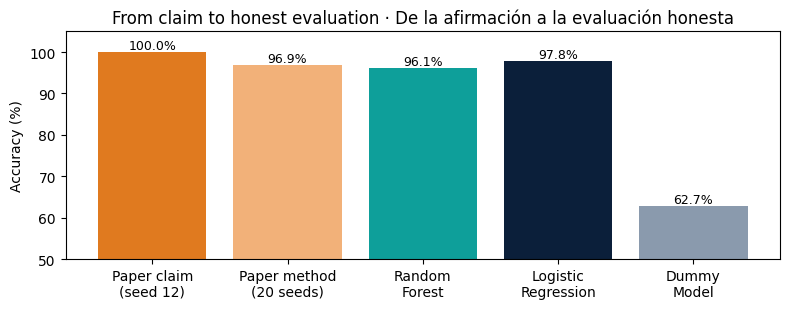

In [ ]:
import matplotlib.pyplot as plt

candidate_name = (
    "Candidate thesis model: Random Forest / Modelo candidato de tesis"
)
baseline_name = (
    "Baseline: logistic regression / Modelo base"
)
dummy_name = (
    "Dumb model: always guess 'benign' / Modelo tonto"
)

labels = [
    "Paper claim\n(seed 12)",
    "Paper method\n(20 seeds)",
    "Random\nForest",
    "Logistic\nRegression",
    "Dummy\nModel"
]

vals = [
    res[12],
    res.mean(),
    report.loc[candidate_name, "Mean / Media"],
    report.loc[baseline_name, "Mean / Media"],
    report.loc[dummy_name, "Mean / Media"]
]

colors = [
    "#E07A1F",
    "#F2B179",
    "#0E9F9A",
    "#0B1F3A",
    "#8A9AAD"
]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(labels, np.array(vals) * 100, color=colors)

for i, value in enumerate(vals):
    ax.text(
        i,
        value * 100 + 0.8,
        f"{value:.1%}",
        ha="center",
        fontsize=9
    )

ax.set_ylim(50, 105)
ax.set_ylabel("Accuracy (%)")
ax.set_title(
    "From claim to honest evaluation · "
    "De la afirmación a la evaluación honesta"
)

plt.tight_layout()
plt.show()

## 5. Reproducibility Report

In [ ]:
candidate_name = (
    "Candidate thesis model: Random Forest / Modelo candidato de tesis"
)
baseline_name = (
    "Baseline: logistic regression / Modelo base"
)

candidate = report.loc[candidate_name]
baseline = report.loc[baseline_name]

difference = (
    baseline["Mean / Media"] -
    candidate["Mean / Media"]
) * 100

print("REPRODUCTION REPORT · INFORME DE REPRODUCCIÓN")
print("-" * 70)

print(
    f"Same number again? / ¿Mismo número?          : "
    f"YES / SÍ, {res[12]:.1%}"
)

print(
    "Is the original claim valid? / ¿Es válida?   : NO"
)

print(
    "Problems / Problemas                         : "
    "lucky seed; duplicate patients; data leakage"
)

print(
    f"Candidate Random Forest / Modelo candidato   : "
    f"{candidate['Mean / Media']:.1%} ± "
    f"{candidate['SD / DE']:.1%}"
)

print(
    f"Logistic Regression baseline / Modelo base   : "
    f"{baseline['Mean / Media']:.1%} ± "
    f"{baseline['SD / DE']:.1%}"
)

print(
    f"Baseline advantage / Ventaja del modelo base : "
    f"{difference:.1f} percentage points"
)

print(
    f"Environment / Entorno                        : "
    f"Python {platform.python_version()}, "
    f"scikit-learn {sklearn.__version__}"
)

print("-" * 70)

print(
    "Conclusion: Logistic Regression performed better than "
    "the Random Forest candidate model."
)

REPRODUCTION REPORT · INFORME DE REPRODUCCIÓN
----------------------------------------------------------------------
Same number again? / ¿Mismo número?          : YES / SÍ, 100.0%
Is the original claim valid? / ¿Es válida?   : NO
Problems / Problemas                         : lucky seed; duplicate patients; data leakage
Candidate Random Forest / Modelo candidato   : 96.1% ± 1.7%
Logistic Regression baseline / Modelo base   : 97.8% ± 1.4%
Baseline advantage / Ventaja del modelo base : 1.8 percentage points
Environment / Entorno                        : Python 3.13.16, scikit-learn 1.6.1
----------------------------------------------------------------------
Conclusion: Logistic Regression performed better than the Random Forest candidate model.


## 6. Interpretation and Conclusion

The reported 100% accuracy can be reproduced with the specified seed, but the original claim is not methodologically valid because the workflow contains duplicated observations and data leakage. Under repeated stratified cross validation, Logistic Regression performs better than Random Forest on the demonstration dataset.

Random Forest remains a relevant candidate for the doctoral research because it can represent nonlinear relationships among academic, administrative, contextual, and temporal variables. However, it should only be preferred over simpler alternatives if it demonstrates consistent improvements in discrimination, calibration, fairness, performance under temporal validation, and practical usefulness. The final comparison must use institutional student data and a validation design that prevents data leakage and reflects the model's intended application.